In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

# Load the Wisconsin Breast Cancer dataset
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name="diagnosis")

print("Dataset shape:", X.shape)
print("Number of samples:", len(y))
print("Number of features:", X.shape[1])
print("\nClass distribution:")
print(y.value_counts())

X.head()


Dataset shape: (569, 30)
Number of samples: 569
Number of features: 30

Class distribution:
diagnosis
1    357
0    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Step 1: Split the dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X.values,
    y.values,
    test_size=0.2,
    random_state=42,
    stratify=y.values
)

# Step 2: Standardize the features
# Fit only on training data to avoid data leakage
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Step 3: Display results
print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining class distribution:")
print(np.unique(y_train, return_counts=True))

print("\nTesting class distribution:")
print(np.unique(y_test, return_counts=True))

print("\nTraining feature mean (first 5):")
print(np.round(X_train.mean(axis=0)[:5], 4))

print("\nTraining feature std (first 5):")
print(np.round(X_train.std(axis=0)[:5], 4))


Training set shape: (455, 30)
Testing set shape: (114, 30)

Training class distribution:
(array([0, 1]), array([170, 285]))

Testing class distribution:
(array([0, 1]), array([42, 72]))

Training feature mean (first 5):
[-0.  0. -0.  0.  0.]

Training feature std (first 5):
[1. 1. 1. 1. 1.]


In [ ]:

# Step 3: MLP Neural Network implemented with NumPy

np.random.seed(42)

input_size = X_train.shape[1]
hidden_size = 16
learning_rate = 0.01
epochs = 3000

# Initialize weights and biases
W1 = np.random.randn(input_size, hidden_size) * np.sqrt(2 / input_size)
b1 = np.zeros((1, hidden_size))

W2 = np.random.randn(hidden_size, 1) * np.sqrt(1 / hidden_size)
b2 = np.zeros((1, 1))

def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

def relu(z):
    return np.maximum(0, z)

def relu_derivative(z):
    return (z > 0).astype(float)

y_train_col = y_train.reshape(-1, 1)
loss_history = []

# Training
for epoch in range(epochs):

    # Forward propagation
    Z1 = X_train @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = sigmoid(Z2)

    # Binary cross-entropy loss
    eps = 1e-10
    loss = -np.mean(
        y_train_col * np.log(A2 + eps)
        + (1 - y_train_col) * np.log(1 - A2 + eps)
    )
    loss_history.append(loss)

    # Backpropagation
    m = X_train.shape[0]

    dZ2 = A2 - y_train_col
    dW2 = A1.T @ dZ2 / m
    db2 = np.mean(dZ2, axis=0, keepdims=True)

    dZ1 = (dZ2 @ W2.T) * relu_derivative(Z1)
    dW1 = X_train.T @ dZ1 / m
    db1 = np.mean(dZ1, axis=0, keepdims=True)

    # Update parameters
    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1
    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss:.4f}")

# Test predictions
Z1_test = X_test @ W1 + b1
A1_test = relu(Z1_test)
Z2_test = A1_test @ W2 + b2

mlp_prob = sigmoid(Z2_test).flatten()
mlp_pred = (mlp_prob >= 0.5).astype(int)

mlp_accuracy = np.mean(mlp_pred == y_test)

print("\nMLP Test Accuracy:", round(mlp_accuracy, 4))
print("Correct predictions:", np.sum(mlp_pred == y_test))
print("Total test samples:", len(y_test))


Epoch 500/3000, Loss: 0.1278
Epoch 1000/3000, Loss: 0.0903
Epoch 1500/3000, Loss: 0.0739
Epoch 2000/3000, Loss: 0.0644
Epoch 2500/3000, Loss: 0.0578
Epoch 3000/3000, Loss: 0.0531

MLP Test Accuracy: 0.9649
Correct predictions: 110
Total test samples: 114


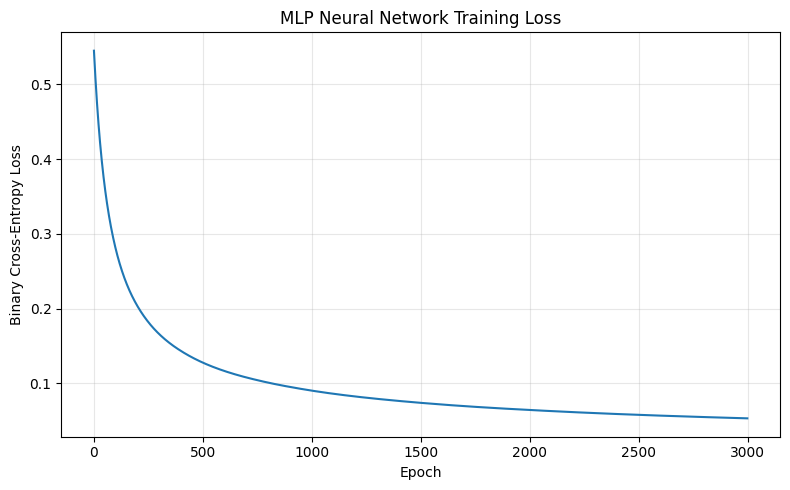

In [ ]:

plt.figure(figsize=(8, 5))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("MLP Neural Network Training Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Step 4: Bayesian Logistic Regression using MAP estimation
# Implemented from scratch with NumPy

np.random.seed(42)

n_features = X_train.shape[1]

# Initialize parameters
w = np.zeros(n_features)
b = 0.0

learning_rate_bayes = 0.05
epochs_bayes = 3000
prior_variance = 10.0

bayes_loss_history = []

for epoch in range(epochs_bayes):

    # Forward pass
    z = X_train @ w + b
    probabilities = sigmoid(z)

    # Negative log-likelihood
    eps = 1e-10
    nll = -np.mean(
        y_train * np.log(probabilities + eps)
        + (1 - y_train) * np.log(1 - probabilities + eps)
    )

    # Gaussian prior penalty (MAP)
    prior_penalty = np.sum(w ** 2) / (
        2 * prior_variance * len(y_train)
    )

    loss = nll + prior_penalty
    bayes_loss_history.append(loss)

    # Gradients
    error = probabilities - y_train

    dw = (
        X_train.T @ error / len(y_train)
        + w / (prior_variance * len(y_train))
    )

    db = np.mean(error)

    # Parameter updates
    w -= learning_rate_bayes * dw
    b -= learning_rate_bayes * db

    if (epoch + 1) % 500 == 0:
        print(f"Epoch {epoch+1}/{epochs_bayes}, Loss: {loss:.4f}")

# Test predictions
bayes_prob = sigmoid(X_test @ w + b)
bayes_pred = (bayes_prob >= 0.5).astype(int)

bayes_accuracy = np.mean(bayes_pred == y_test)

print("\nBayesian MAP Test Accuracy:", round(bayes_accuracy, 4))
print("Correct predictions:", np.sum(bayes_pred == y_test))
print("Total test samples:", len(y_test))


Epoch 500/3000, Loss: 0.0763
Epoch 1000/3000, Loss: 0.0654
Epoch 1500/3000, Loss: 0.0607
Epoch 2000/3000, Loss: 0.0580
Epoch 2500/3000, Loss: 0.0561
Epoch 3000/3000, Loss: 0.0547

Bayesian MAP Test Accuracy: 0.9737
Correct predictions: 111
Total test samples: 114


In [ ]:
# Compare the two models

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

results = pd.DataFrame({
    "Model": ["MLP Neural Network", "Bayesian MAP Logistic Regression"],
    "Accuracy": [
        accuracy_score(y_test, mlp_pred),
        accuracy_score(y_test, bayes_pred)
    ],
    "Precision": [
        precision_score(y_test, mlp_pred, pos_label=0),
        precision_score(y_test, bayes_pred, pos_label=0)
    ],
    "Recall": [
        recall_score(y_test, mlp_pred, pos_label=0),
        recall_score(y_test, bayes_pred, pos_label=0)
    ],
    "F1 Score": [
        f1_score(y_test, mlp_pred, pos_label=0),
        f1_score(y_test, bayes_pred, pos_label=0)
    ]
})

print("Model Comparison:")
print(results.round(4).to_string(index=False))

print("\nMLP Confusion Matrix:")
print(confusion_matrix(y_test, mlp_pred, labels=[0, 1]))

print("\nBayesian MAP Confusion Matrix:")
print(confusion_matrix(y_test, bayes_pred, labels=[0, 1]))


Model Comparison:
                           Model  Accuracy  Precision  Recall  F1 Score
              MLP Neural Network    0.9649     0.9318  0.9762    0.9535
Bayesian MAP Logistic Regression    0.9737     0.9535  0.9762    0.9647

MLP Confusion Matrix:
[[41  1]
 [ 3 69]]

Bayesian MAP Confusion Matrix:
[[41  1]
 [ 2 70]]


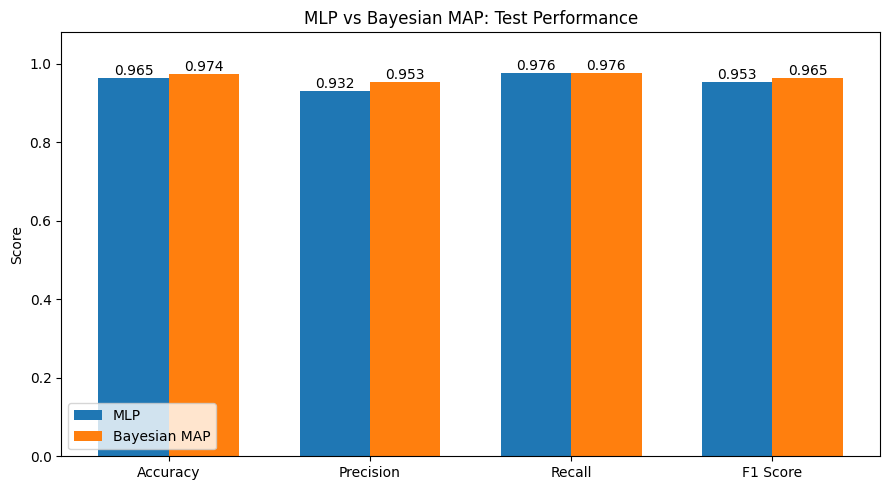

In [ ]:
# Model Performance Comparison

metrics = ["Accuracy", "Precision", "Recall", "F1 Score"]

mlp_scores = results.iloc[0, 1:].astype(float).values
bayes_scores = results.iloc[1, 1:].astype(float).values

x = np.arange(len(metrics))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

bars1 = ax.bar(x - width/2, mlp_scores, width, label="MLP")
bars2 = ax.bar(x + width/2, bayes_scores, width, label="Bayesian MAP")

ax.set_ylabel("Score")
ax.set_title("MLP vs Bayesian MAP: Test Performance")
ax.set_xticks(x)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.08)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.3f}",
            (bar.get_x() + bar.get_width()/2, height),
            ha="center",
            va="bottom"
        )

plt.tight_layout()
plt.savefig("model_comparison.png", dpi=300)
plt.show()
